# Laboratorio 8 — Embeddings contextuales con BERT multilingüe
**CC3092 Deep Learning — Universidad del Valle de Guatemala**

**Entrega final: Task 3 (y Task 4, preguntas teóricas)**

Las Tasks 1 y 2 (Mini-GPT y estrategias de muestreo) están en `Lab8_S13_Task1y2.ipynb`. En este notebook se usa `bert-base-multilingual-cased` preentrenado para mostrar empíricamente que los embeddings **contextuales** distinguen los significados de una palabra polisémica (*banco*, *copa*, *vela*), cosa que un embedding **estático** como Word2Vec no puede hacer.

> Pensado para Google Colab. Solo descarga modelos preentrenados: BERT (~700 MB) desde HuggingFace y Word2Vec (~1.6 GB) desde `gensim-data`. No entrena nada. GPU opcional.

In [1]:
# gensim no viene preinstalado en Colab; transformers, torch y scikit-learn si.
!pip -q install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 32.9 MB/s eta 0:00:00


In [2]:
import torch, re, json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
pd.set_option('display.precision', 4)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.11.0+cu130 | device: cuda


## Task 3.1 — Extracción de embeddings contextuales

Se carga `bert-base-multilingual-cased` (12 capas, $d_{model}=768$, vocabulario WordPiece de ~119k subpalabras en 104 idiomas). Para cada oración se toma la salida de la **última capa** (`last_hidden_state`, de forma $(T, 768)$) y se extrae el vector de la posición de la palabra objetivo, **no** el de `[CLS]`.

**Subpalabras.** WordPiece puede partir una palabra en varias piezas (p. ej. `ve`, `##la`). Para encontrar las piezas que forman la palabra objetivo se usa el `offset_mapping` del tokenizador (el rango de caracteres de cada token en la oración original). Si la palabra queda en una sola pieza se usa ese vector tal cual; si se parte en varias, se promedian los vectores de sus piezas, que es la convención habitual para obtener un vector por palabra. Abajo se imprime la tokenización de cada caso para dejar constancia de cuál ocurrió.

In [3]:
MODEL_NAME = 'bert-base-multilingual-cased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()   # eval(): sin dropout -> salida determinista
print(f'Capas: {bert.config.num_hidden_layers} | d_model: {bert.config.hidden_size} | vocab: {bert.config.vocab_size:,}')

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Capas: 12 | d_model: 768 | vocab: 119,547


In [4]:
# Oraciones del enunciado: (id, oracion, palabra objetivo, significado)
DATA = [
    ('banco_1', 'El banco central anunció una subida de tasas de interés.',     'banco', 'banco: institución financiera'),
    ('banco_2', 'Me senté en el banco del parque a leer el periódico.',          'banco', 'banco: asiento'),
    ('banco_3', 'El banco de peces se movió velozmente ante el tiburón.',        'banco', 'banco: cardumen'),
    ('copa_1',  'El equipo levantó la copa del torneo ante miles de aficionados.', 'copa', 'copa: trofeo'),
    ('copa_2',  'Sirvió una copa de vino tinto para acompañar la cena.',         'copa',  'copa: recipiente para beber'),
    ('vela_1',  'El velero desplegó su vela para aprovechar el viento.',         'vela',  'vela: de embarcación'),
    ('vela_2',  'Encendió una vela para iluminar el cuarto durante el apagón.',  'vela',  'vela: de cera'),
]

@torch.no_grad()
def word_embedding(sentence, word):
    # 1) Ubicar la palabra en la oracion como palabra completa (\b evita que 'vela' coincida dentro de 'velero')
    m = re.search(rf'\b{re.escape(word)}\b', sentence)
    assert m is not None, f'No se encontro "{word}" en: {sentence}'
    w_start, w_end = m.span()
    # 2) Tokenizar con offsets: cada token trae el rango [ini, fin) de caracteres que cubre
    enc = tokenizer(sentence, return_tensors='pt', return_offsets_mapping=True)
    offsets = enc.pop('offset_mapping')[0].tolist()
    # 3) Forward: H = salida de la ultima capa, forma (T, 768)
    H = bert(**{k: v.to(device) for k, v in enc.items()}).last_hidden_state[0]
    # 4) Indices de las subpalabras que caen dentro de la palabra objetivo.
    #    [CLS] y [SEP] tienen offset (0, 0), asi que nunca se seleccionan.
    idx = [i for i, (s, e) in enumerate(offsets) if e > s and s >= w_start and e <= w_end]
    assert idx, 'La palabra objetivo no quedo alineada con ningun token'
    pieces = tokenizer.convert_ids_to_tokens(enc['input_ids'][0, idx])
    # 5) Una pieza -> su vector; varias piezas -> promedio de sus vectores
    vec = H[idx].mean(dim=0).cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])
    return vec, idx, pieces, tokens

emb, info = {}, []
for sid, sent, word, sense in DATA:
    vec, idx, pieces, tokens = word_embedding(sent, word)
    emb[sid] = vec
    info.append({'id': sid, 'palabra': word, 'significado': sense, 'posiciones': idx,
                 'subpalabras': ' + '.join(pieces), 'dim': vec.shape[0]})
    print(f'{sid:8s} {tokens}')

E = np.stack([emb[d[0]] for d in DATA])     # matriz (7, 768)
assert E.shape == (7, 768)
pd.DataFrame(info)

banco_1  ['[CLS]', 'El', 'banco', 'central', 'anunció', 'una', 'sub', '##ida', 'de', 'tasa', '##s', 'de', 'interés', '.', '[SEP]']
banco_2  ['[CLS]', 'Me', 'sent', '##é', 'en', 'el', 'banco', 'del', 'parque', 'a', 'leer', 'el', 'periódico', '.', '[SEP]']
banco_3  ['[CLS]', 'El', 'banco', 'de', 'peces', 'se', 'mo', '##vió', 'vel', '##oz', '##mente', 'ante', 'el', 'ti', '##bur', '##ón', '.', '[SEP]']
copa_1   ['[CLS]', 'El', 'equipo', 'leva', '##ntó', 'la', 'copa', 'del', 'torneo', 'ante', 'miles', 'de', 'af', '##icionados', '.', '[SEP]']
copa_2   ['[CLS]', 'Sir', '##vió', 'una', 'copa', 'de', 'vino', 'tin', '##to', 'para', 'ac', '##om', '##pa', '##ñar', 'la', 'cena', '.', '[SEP]']
vela_1   ['[CLS]', 'El', 'vele', '##ro', 'des', '##ple', '##gó', 'su', 'vela', 'para', 'ap', '##rove', '##char', 'el', 'viento', '.', '[SEP]']
vela_2   ['[CLS]', 'En', '##cend', '##ió', 'una', 'vela', 'para', 'il', '##umi', '##nar', 'el', 'cuarto', 'durante', 'el', 'apa', '##gón', '.', '[SEP]']


,id,palabra,significado,posiciones,subpalabras,dim
0,banco_1,banco,banco: institución financiera,[2],banco,768
1,banco_2,banco,banco: asiento,[6],banco,768
2,banco_3,banco,banco: cardumen,[2],banco,768
3,copa_1,copa,copa: trofeo,[6],copa,768
4,copa_2,copa,copa: recipiente para beber,[4],copa,768
5,vela_1,vela,vela: de embarcación,[8],vela,768
6,vela_2,vela,vela: de cera,[5],vela,768


## Task 3.2 (a) — Similitud coseno entre contextos de la misma palabra

$$\text{sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}^\top \mathbf{v}}{\lVert \mathbf{u} \rVert \cdot \lVert \mathbf{v} \rVert}$$

Se calcula para todos los pares de contextos de la misma palabra: 3 pares para *banco* y 1 para *copa* y para *vela*.

In [5]:
def cosine(u, v):
    # sim(u, v) = u^T v / (||u|| * ||v||)
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

sense_of = {d[0]: d[3] for d in DATA}
word_of  = {d[0]: d[2] for d in DATA}

rows = []
for w in ['banco', 'copa', 'vela']:
    ids = [d[0] for d in DATA if d[2] == w]
    for a, b in itertools.combinations(ids, 2):
        rows.append({'palabra': w, 'contexto 1': sense_of[a].split(': ')[1], 'contexto 2': sense_of[b].split(': ')[1],
                     'par': f'{a} vs {b}', 'cos BERT': cosine(emb[a], emb[b])})
bert_pairs = pd.DataFrame(rows)
bert_pairs

,palabra,contexto 1,contexto 2,par,cos BERT
0,banco,institución financiera,asiento,banco_1 vs banco_2,0.5753
1,banco,institución financiera,cardumen,banco_1 vs banco_3,0.6603
2,banco,asiento,cardumen,banco_2 vs banco_3,0.6496
3,copa,trofeo,recipiente para beber,copa_1 vs copa_2,0.5667
4,vela,de embarcación,de cera,vela_1 vs vela_2,0.7999


**Referencia para interpretar los valores.** Los embeddings de la última capa de BERT son anisotrópicos: todos ocupan un cono estrecho del espacio, así que incluso dos palabras sin relación tienen similitud coseno positiva y relativamente alta (Ethayarajh, 2019). Por eso, para saber si un valor es "alto" o "bajo", se compara contra la similitud entre palabras **distintas** (*banco* vs *copa*, etc.). La matriz completa de $7 \times 7$ permite ver las dos cosas a la vez.

Misma palabra, distinto sentido  (n=5): media 0.6504 | rango [0.5667, 0.7999]
Palabras distintas (referencia) (n=16): media 0.3912 | rango [0.3230, 0.4936]


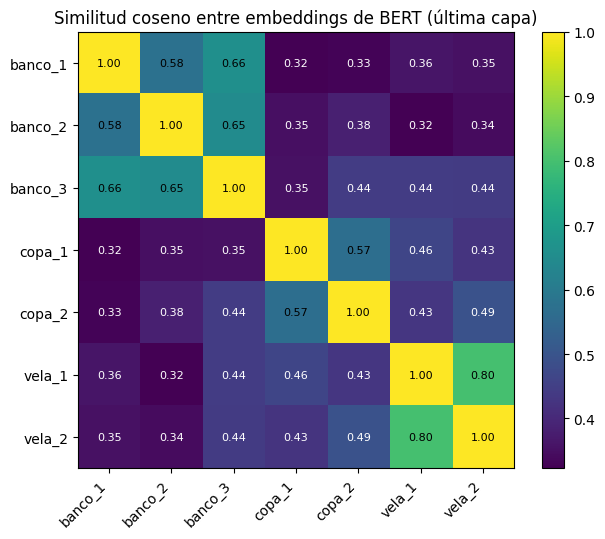

In [6]:
labels = [d[0] for d in DATA]
S = np.array([[cosine(emb[a], emb[b]) for b in labels] for a in labels])

same_word = [S[i, j] for i, j in itertools.combinations(range(7), 2) if word_of[labels[i]] == word_of[labels[j]]]
diff_word = [S[i, j] for i, j in itertools.combinations(range(7), 2) if word_of[labels[i]] != word_of[labels[j]]]
print(f'Misma palabra, distinto sentido  (n={len(same_word)}): media {np.mean(same_word):.4f} | rango [{min(same_word):.4f}, {max(same_word):.4f}]')
print(f'Palabras distintas (referencia) (n={len(diff_word)}): media {np.mean(diff_word):.4f} | rango [{min(diff_word):.4f}, {max(diff_word):.4f}]')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap='viridis', vmin=S[~np.eye(7, dtype=bool)].min(), vmax=1)
ax.set_xticks(range(7)); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(7)); ax.set_yticklabels(labels)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{S[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='black' if S[i, j] > S.mean() else 'white')
ax.set_title('Similitud coseno entre embeddings de BERT (última capa)')
fig.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
plt.savefig('bert_cos_matrix.png', dpi=150); plt.show()

### Task 3.2 (a, segunda parte) — Comparación con Word2Vec estático

Se usa `word2vec-google-news-300` de `gensim-data`, que es el único modelo **Word2Vec** del catálogo de `gensim.downloader` (los demás son GloVe, FastText o ConceptNet). Fue entrenado sobre Google News, mayormente en inglés, pero su vocabulario de 3 millones de entradas incluye *banco*, *copa* y *vela*.

En un embedding estático la tabla de búsqueda asigna **un solo vector por tipo de palabra**: $\mathbf{v}_{\text{banco}} = E[\text{banco}]$, sin importar la oración. Por lo tanto, la similitud entre "banco (financiero)" y "banco (asiento)" es $\text{sim}(\mathbf{v}, \mathbf{v}) = 1$ por construcción. Se calcula de todos modos, aplicando el mismo procedimiento a cada oración, para que la comparación con BERT sea directa.

> La descarga es de ~1.6 GB y cargarlo usa ~3.6 GB de RAM (Colab tiene ~12 GB).

In [7]:
import gensim.downloader as api
w2v = api.load('word2vec-google-news-300')
print(f'Vocabulario Word2Vec: {len(w2v.key_to_index):,} | dimension: {w2v.vector_size}')
for w in ['banco', 'copa', 'vela']:
    print(f'{w!r} en el vocabulario: {w in w2v.key_to_index} (rango de frecuencia {w2v.key_to_index.get(w):,})')

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulario Word2Vec: 3,000,000 | dimension: 300
'banco' en el vocabulario: True (rango de frecuencia 929,039)
'copa' en el vocabulario: True (rango de frecuencia 1,068,243)
'vela' en el vocabulario: True (rango de frecuencia 894,302)


In [8]:
# Vector estatico por oracion: se busca la palabra objetivo en la tabla de embeddings.
# El contexto no interviene en ningun momento, asi que las 3 'instancias' de banco son el mismo vector.
w2v_emb = {sid: w2v[word] for sid, _, word, _ in DATA}

comp = bert_pairs.copy()
comp['cos Word2Vec'] = [cosine(w2v_emb[p.split(' vs ')[0]], w2v_emb[p.split(' vs ')[1]]) for p in comp['par']]
comp['diferencia (W2V - BERT)'] = comp['cos Word2Vec'] - comp['cos BERT']
comp

,palabra,contexto 1,contexto 2,par,cos BERT,cos Word2Vec,diferencia (W2V - BERT)
0,banco,institución financiera,asiento,banco_1 vs banco_2,0.5753,1.0,0.4247
1,banco,institución financiera,cardumen,banco_1 vs banco_3,0.6603,1.0,0.3397
2,banco,asiento,cardumen,banco_2 vs banco_3,0.6496,1.0,0.3504
3,copa,trofeo,recipiente para beber,copa_1 vs copa_2,0.5667,1.0,0.4333
4,vela,de embarcación,de cera,vela_1 vs vela_2,0.7999,1.0,0.2001


In [9]:
# Vecinos mas cercanos del vector estatico: muestran que un solo vector tiene que representar
# a la vez todos los sentidos de la palabra en el corpus (aqui, noticias mayormente en ingles).
for w in ['banco', 'copa', 'vela']:
    print(f'{w:6s} ->', ', '.join(f'{n} ({s:.2f})' for n, s in w2v.most_similar(w, topn=8)))

banco  -> arriba (0.52), forza (0.52), deus (0.51), apenas (0.51), próxima (0.51), mesi (0.50), nostra (0.50), nuova (0.50)
copa   -> boca (0.63), diez (0.62), você (0.62), ojos (0.62), solamente (0.62), el_es (0.61), fresca (0.61), comida (0.61)
vela   -> roberto (0.62), feliz (0.61), eto (0.60), tú (0.60), clase (0.60), suerte (0.59), quién (0.59), eso (0.59)


## Task 3.2 (b) — Visualización con PCA

Se proyectan los 7 vectores de 768 dimensiones a 2 componentes principales. Cada punto es una **instancia** de la palabra en su oración; el color indica el **significado** (7 colores, uno por sentido) y la forma del marcador indica la palabra.

Varianza explicada: PC1 35.0% | PC2 23.5% | total 58.6%


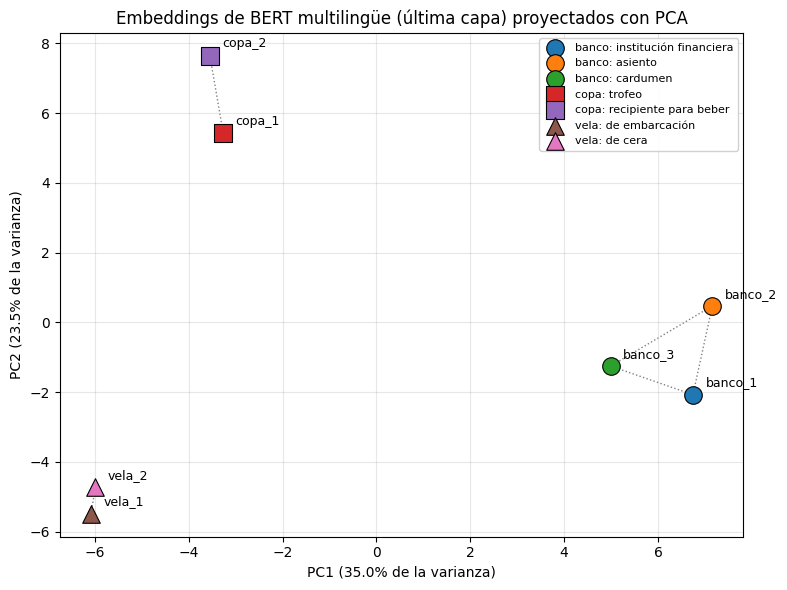

Distancia euclidiana en el plano PCA entre instancias de la misma palabra:
  banco_1 - banco_2: 2.580
  banco_1 - banco_3: 1.936
  banco_2 - banco_3: 2.770
  copa_1 - copa_2: 2.236
  vela_1 - vela_2: 0.766


In [10]:
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(E)        # PCA centra los datos y proyecta sobre los 2 ejes de mayor varianza
ev = pca.explained_variance_ratio_
print(f'Varianza explicada: PC1 {ev[0]:.1%} | PC2 {ev[1]:.1%} | total {ev.sum():.1%}')

markers = {'banco': 'o', 'copa': 's', 'vela': '^'}
colors  = plt.cm.tab10(np.arange(7))
fig, ax = plt.subplots(figsize=(8, 6))
for i, (sid, sent, word, sense) in enumerate(DATA):
    ax.scatter(Z[i, 0], Z[i, 1], s=160, marker=markers[word], color=colors[i],
               edgecolor='black', linewidth=0.8, label=sense, zorder=3)
    ax.annotate(sid, (Z[i, 0], Z[i, 1]), textcoords='offset points', xytext=(9, 6), fontsize=9)
# Lineas punteadas entre instancias de la misma palabra
for w in markers:
    ii = [i for i, d in enumerate(DATA) if d[2] == w]
    for a, b in itertools.combinations(ii, 2):
        ax.plot(Z[[a, b], 0], Z[[a, b], 1], ls=':', color='gray', lw=1, zorder=1)
ax.set_xlabel(f'PC1 ({ev[0]:.1%} de la varianza)'); ax.set_ylabel(f'PC2 ({ev[1]:.1%} de la varianza)')
ax.set_title('Embeddings de BERT multilingüe (última capa) proyectados con PCA')
ax.legend(fontsize=8, loc='best', framealpha=0.9); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('bert_pca.png', dpi=150); plt.show()

# Con Word2Vec, las instancias de la misma palabra caerian exactamente en el mismo punto.
print('Distancia euclidiana en el plano PCA entre instancias de la misma palabra:')
for w in markers:
    ii = [i for i, d in enumerate(DATA) if d[2] == w]
    for a, b in itertools.combinations(ii, 2):
        print(f'  {DATA[a][0]} - {DATA[b][0]}: {np.linalg.norm(Z[a] - Z[b]):.3f}')

In [11]:
# Se guardan los resultados numericos para el reporte
results = {
    'tokenizacion': info,
    'pares': comp.to_dict(orient='records'),
    'matriz_cos': {'labels': labels, 'S': S.round(6).tolist()},
    'misma_palabra_media': float(np.mean(same_word)), 'distinta_palabra_media': float(np.mean(diff_word)),
    'distinta_palabra_rango': [float(min(diff_word)), float(max(diff_word))],
    'pca': {'explained_variance_ratio': ev.tolist(), 'Z': Z.round(6).tolist()},
    'w2v_vecinos': {w: w2v.most_similar(w, topn=8) for w in ['banco', 'copa', 'vela']},
    'w2v_rangos': {w: w2v.key_to_index[w] for w in ['banco', 'copa', 'vela']},
}
with open('resultados_task3.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2, default=lambda o: o.tolist() if hasattr(o, 'tolist') else str(o))
print('Guardado resultados_task3.json')

Guardado resultados_task3.json


## Task 4 — Preguntas teóricas

Las respuestas de la Task 4 se encuentran en el documento PDF de la entrega.